# 22 Alarme bewerten

- Setzt auf dem finalen Modell auf: Netzvergleich (Notebook 20) und Tagesmonitor mit CUSUM (Notebook 21), zusammengeführt in `stationsblatt.rechne`.
- Fragen: Wie hängen Treffer und Alarmlast von der Schwelle h ab? Warnt der CUSUM vor? Ergibt Netzvergleich plus Verschlechterungsalarm eine brauchbare Priorität? Gibt es Fehlerbilder, spielt das Baujahr eine Rolle?
- Logik in `src/alarmbewertung.py`. Ausgaben nur mit Zählernummern.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import alarmbewertung as ab
from src import befundcodes as bc
from src import fallsammlung as fs
from src import netzvergleich as nv
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
r = erg["tagesmonitor"]
termine = erg["termine"]
kodiert = bc.kodiere_begehungen()
faelle = tm.faelle(kodiert)
status = bl.statustabelle(erg)
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print(f"{len(r['alarme'])} CUSUM-Alarme bei h = {tm.CUSUM_H:g}, "
      f"{ab.heiztage(r['verlauf'])} überwachte Heiztage")

100 Stundenreihen aus NB 00, gerechnet in 90 s
592 CUSUM-Alarme bei h = 5, 37452 überwachte Heiztage


## 1 Schwelle h

- h ist die aufsummierte Abweichung (in Streuungseinheiten), die ein CUSUM-Konto erreichen muss, bis Alarm kommt. Standard h = 5, aus dem Normalverhaltensmodell übernommen, nicht kalibriert.
- Alarme für h = 5 bis 20 neu gerechnet, jeweils mit dem Treffertest aus Notebook 21. Der Deckel des Kontos wächst als 2 h mit.

,h,alarme,stationen_mit_alarm,je_100_heiztage,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,5.0,592,87,1.581,43,23,0.535,0.267,2.006,0.000
3,8.0,386,83,1.031,43,18,0.419,0.242,1.730,0.008
6,10.0,321,80,0.857,43,15,0.349,0.254,1.373,0.108
9,15.0,247,76,0.660,43,14,0.326,0.192,1.697,0.026
12,20.0,194,73,0.518,43,11,0.256,0.162,1.577,0.078


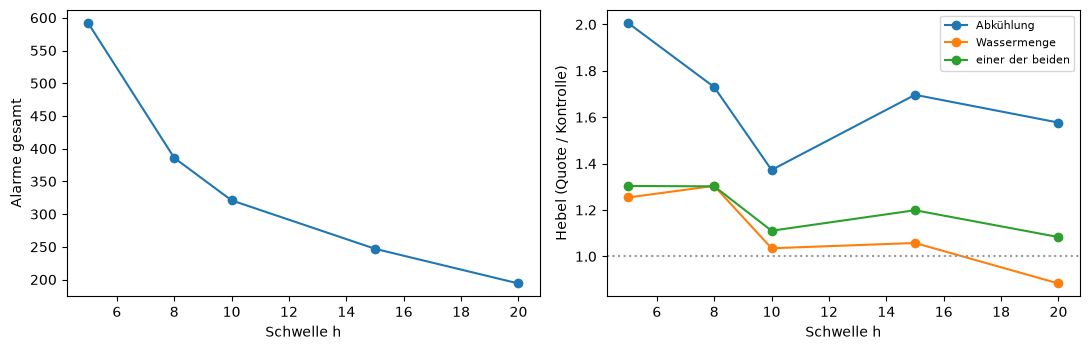

In [2]:
schwelle = ab.schwellentest(r["verlauf"], faelle, termine)
abk = schwelle[schwelle["pruefung"] == "Abkühlung"]
display(abk[["h", "alarme", "stationen_mit_alarm", "je_100_heiztage", "Faelle",
             "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]]
        .round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(abk["h"], abk["alarme"], "o-")
ax[0].set_xlabel("Schwelle h"), ax[0].set_ylabel("Alarme gesamt")
for name, g in schwelle.groupby("pruefung", sort=False):
    ax[1].plot(g["h"], g["Hebel"], "o-", label=name)
ax[1].axhline(1, color="0.6", ls=":")
ax[1].set_xlabel("Schwelle h"), ax[1].set_ylabel("Hebel (Quote / Kontrolle)")
ax[1].legend(fontsize=8)
fig.tight_layout()

- Bei h = 8 fallen die Alarme auf etwa zwei Drittel (386 statt 592).
- Der Hebel im Abkühlungskanal bleibt bis h = 8 signifikant, danach unruhig: Bei 43 Begehungen verschiebt jede die Quote um gut zwei Prozentpunkte. Die Wassermenge ist bei keiner Schwelle signifikant.
- Keine klar beste Schwelle; h = 8 ist ein Kandidat, falls die Alarmlast stört.

## 2 Richtung der Alarme und Vorwarnung

- Verschlechtert heißt weniger Abkühlung (kWh/m³ fällt) oder mehr Wasser bei gleichem Wetter, verbessert die Gegenrichtung. Für einen Fehlermelder zählen nur Verschlechterungen.
- Treffertest nach Richtung, dazu ein Vorlauffenster 180 bis 7 Tage vor der Begehung: Mehr Verschlechterungsalarme als bei den Kontrollen hieße Vorwarnung.

In [3]:
richt = ab.bewerte_richtung(r["alarme"])
display(pd.crosstab(richt["kanal"], richt["bewertung"], margins=True))
rt = ab.richtungstest(r["alarme"], faelle, r["verlauf"], termine)
display(rt.round(3))

bewertung,besser,schlechter,All
kanal,,,
kwh_pro_m3,95,160,255
log_volumen,206,131,337
All,301,291,592


,richtung,fenster,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,alle,um die Begehung,43,30,0.698,0.535,1.303,0.022
1,alle,davor,32,13,0.406,0.540,0.752,0.955
2,schlechter,um die Begehung,43,16,0.372,0.351,1.059,0.443
3,schlechter,davor,32,11,0.344,0.365,0.941,0.663
4,besser,um die Begehung,43,25,0.581,0.265,2.197,0.000
5,besser,davor,32,5,0.156,0.333,0.470,0.993


- Wichtigster Befund: Der Hebel von rund 2 aus Notebook 21 kommt fast ganz aus Alarmen Richtung besser (Hebel um 2,2, p < 0,001).
- Verschlechterungsalarme sind um die Begehung nicht häufiger als bei den Kontrollen (Hebel um 1,1), im halben Jahr davor auch nicht (unter 1). Im Vorlauffenster nur 32 Fälle.

## 3 Priorität aus Netzvergleich und Verschlechterungsalarm

- Je Station und Kernwinter. Hoch heißt im Netz auffällig und mindestens ein Verschlechterungsalarm in der Heizperiode (1. Oktober bis 30. April), mittel eins von beiden, niedrig keins.

In [4]:
prio = erg["prioritaet"]
display(pd.crosstab(prio["winter"], prio["prioritaet"], margins=True)
        [[*ab.STUFEN, "All"]])
tafel = pd.crosstab(prio["auffaellig"], prio["alarme_schlechter"] > 0)
print("Netz auffällig gegen Verschlechterungsalarm:")
display(tafel)
print(f"Fisher zweiseitig p = {stats.fisher_exact(tafel.to_numpy()).pvalue:.2f}")

prioritaet,hoch,mittel,niedrig,All
winter,,,,
22/23,5,24,12,41
23/24,2,33,50,85
24/25,9,44,32,85
All,16,101,94,211


Netz auffällig gegen Verschlechterungsalarm:


alarme_schlechter,False,True
auffaellig,,
False,94,89
True,12,16


Fisher zweiseitig p = 0.42


- Netzauffälligkeit und Verschlechterungsalarm hängen nicht zusammen: Der Netzvergleich misst den Zustand gegenüber den anderen, der CUSUM eine Änderung gegenüber der eigenen Vergangenheit.
- Validierung an der ersten Begehung mit Freitext innerhalb von 400 Tagen nach der Heizperiode. Mechanisch wie in Notebook 15 und 16.

In [5]:
kat = {"mechanisch": list(fs.MECHANISCH), "ventil": ["ventil_stellantrieb"]}
val = ab.befund_nach_winter(prio, kodiert, kat)
print(f"{len(val)} Stationswinter mit Begehung danach")
display(val.groupby("prioritaet")[["mechanisch", "ventil"]]
        .agg(["size", "sum"]).reindex(list(ab.STUFEN)))
tests = {
    "Netz auffällig -> Ventil": (val["auffaellig"], val["ventil"]),
    "Netz auffällig -> mechanisch": (val["auffaellig"], val["mechanisch"]),
    "Alarm schlechter -> Ventil": (val["alarme_schlechter"] > 0, val["ventil"]),
    "Alarm schlechter -> mechanisch": (val["alarme_schlechter"] > 0,
                                       val["mechanisch"]),
}
display(pd.DataFrame({k: ab.vierfeld(*v) for k, v in tests.items()}).T
        .round(3))

49 Stationswinter mit Begehung danach


mechanisch     ventil    
                 size sum   size sum
prioritaet                          
hoch                1   0      1   0
mittel             17   8     17   5
niedrig            31   8     31   3

,n,merkmal_mit_befund,merkmal_ohne_befund,rest_mit_befund,rest_ohne_befund,quote_merkmal,quote_rest,p (einseitig)
Netz auffällig -> Ventil,49.0,2.0,1.0,6.0,40.0,0.667,0.130,0.065
Netz auffällig -> mechanisch,49.0,2.0,1.0,14.0,32.0,0.667,0.304,0.245
Alarm schlechter -> Ventil,49.0,3.0,13.0,5.0,28.0,0.188,0.152,0.523
Alarm schlechter -> mechanisch,49.0,6.0,10.0,10.0,23.0,0.375,0.303,0.424


- Nur der Netzvergleich zeigt eine Tendenz: Von 3 auffälligen Stationswintern mit Begehung danach hatten 2 einen Ventilbefund, von den übrigen 46 nur 6 (p um 0,07).
- Der Verschlechterungsalarm trennt weder Ventil- noch mechanische Befunde; die beiden auffälligen Winter mit Ventilbefund stehen ohne Alarm nur auf mittel. Hoch ist damit nicht besser begründet als „im Netz auffällig“.
- Aktueller Stand je Station:

In [6]:
aktuell = status[status["prioritaet"] != ""]
display(aktuell["prioritaet"].value_counts().reindex(list(ab.STUFEN)))
display(aktuell[aktuell["prioritaet"] == "hoch"]
        [["meter", "winter", "fehlerbild", "alarme_schlechter_winter",
          "n_winter_auffaellig", "chronisch", "letzte_begehung"]]
        .reset_index(drop=True))

prioritaet
hoch        9
mittel     46
niedrig    38

,meter,winter,fehlerbild,alarme_schlechter_winter,n_winter_auffaellig,chronisch,letzte_begehung
0,41566330,24/25,regelung,1,1,False,
1,68956359,24/25,unruhig,4,1,False,2024-09-26
2,68956373,24/25,durchfluss,2,1,False,2025-03-12
3,72135442,24/25,unruhig,2,2,True,2024-09-12
4,72135453,24/25,durchfluss,2,3,True,
5,72167793,24/25,ventil,2,2,True,
6,80912182,24/25,ventil,2,2,True,2024-09-19
7,80956410,24/25,durchfluss,2,1,False,
8,81062289,24/25,regelung,1,1,False,


## 4 Fehlerbild aus dem Muster der schlechten Kennzahlen

- Feste Regeln auf den schlechten Kennzahlen, das erste passende Muster gewinnt.
- Die Texte beschreiben ein Muster und womit es konsistent ist, keine Ursache, keine Maßnahme.

In [7]:
regeln = pd.DataFrame([(c, t) for c, _, t in ab.FEHLERBILDER],
                      columns=["fehlerbild", "text"])
display(regeln)
fb = ab.fehlerbild_je_winter(erg["markiert"], list(erg["kennzahlen"]))
auff = fb[fb["auffaellig"]]
print(f"{len(auff)} auffällige Stationswinter")
display(pd.crosstab(auff["schlechte_kennzahlen"], auff["fehlerbild"]))

,fehlerbild,text
0,ventil,"Volumenstrom folgt der Leistung kaum, kleine S..."
1,durchfluss,viel Wasser bei kleiner Spreizung oder hohem R...
2,unruhig,Kennlinie unruhig; konsistent mit taktender Re...
3,regelung,Volumenstrom folgt der Leistung kaum; konsiste...
4,rücklauf,oft Rücklauf über 50 °C
5,durchfluss_je_kw,hoher Volumenstrom je kW Anschlusswert


28 auffällige Stationswinter


fehlerbild,durchfluss,regelung,unruhig,ventil
schlechte_kennzahlen,,,,
"residuum_sd,flow_spez_lh_kw",0,0,2,0
"spreizung_ref_k,flow_spez_lh_kw",1,0,0,0
"spreizung_ref_k,residuum_sd,flow_spez_lh_kw",2,0,0,0
"spreizung_ref_k,rl_ueber_50_anteil",1,0,0,0
"spreizung_ref_k,rl_ueber_50_anteil,flow_spez_lh_kw",2,0,0,0
"spreizung_ref_k,steigung",0,0,0,4
"spreizung_ref_k,steigung,flow_spez_lh_kw",0,0,0,1
"spreizung_ref_k,steigung,residuum_sd",0,0,0,1
"spreizung_ref_k,steigung,rl_ueber_50_anteil",0,0,0,3


- Häufigstes Muster: flache Steigung mit kleiner Spreizung, also ein Volumenstrom, der kaum mit der Leistung mitgeht und wenig abkühlt. Passt zu einem offenen oder nicht regelnden Ventil.

In [8]:
val_fb = ab.befund_nach_winter(fb, kodiert, kat)
display(pd.crosstab(val_fb["fehlerbild"].replace("", "(keins)"),
                    val_fb["ventil"], margins=True))
display(pd.Series(ab.vierfeld(val_fb["fehlerbild"] == "ventil",
                              val_fb["ventil"]), name="Fehlerbild Ventil -> Ventil")
        .round(3).to_frame().T)

ventil,False,True,All
fehlerbild,,,
(keins),35,4,39
durchfluss_je_kw,1,1,2
unruhig,4,1,5
ventil,1,2,3
All,41,8,49


,n,merkmal_mit_befund,merkmal_ohne_befund,rest_mit_befund,rest_ohne_befund,quote_merkmal,quote_rest,p (einseitig)
Fehlerbild Ventil -> Ventil,49.0,2.0,1.0,6.0,40.0,0.667,0.13,0.065


- Das Fehlerbild Ventil trifft dieselben drei Stationswinter wie „Netz auffällig“, zwei davon mit Ventilbefund. Plausibel, mit drei Fällen aber nicht belegt.
- Für die übrigen Fehlerbilder gibt es kaum Begehungen danach. Die Zuordnung Fehlerbild zu Maßnahme ist offen.

## 5 Baujahr als Kontext

- Baujahr aus dem Freitext der Begehungen (20 Zähler), sonst aus dem Zensus 2022 (100-m-Gitter). Die Geokodierung trifft fast nur die Straße, der Zensuswert ist ein Gebietsmittel.
- Alt heißt vor 1979, vor der ersten Wärmeschutzverordnung. Google Maps und Street View bewusst nicht genutzt, damit keine Kundenadressen an Dritte gehen.

In [9]:
bj = erg["baujahr"]
display(bj.groupby(["baujahr_quelle", "gebiet_baujahr"]).size()
        .rename("zaehler").to_frame())

#Passt das Zensusgebiet zum Baujahr aus dem Freitext?
k = bj[bj["baujahr_begehung"].notna()]
display(pd.crosstab(pd.Series(np.where(k["baujahr_begehung"] < ab.BAUJAHR_GRENZE,
                                       "alt", "neu"), name="Freitext"),
                    k["gebiet_baujahr"].to_numpy()))

zaehler
baujahr_quelle gebiet_baujahr          
               gemischt               7
               unbekannt             16
Begehung       gemischt               2
               unbekannt              7
               überwiegend alt        7
               überwiegend neu        4
Zensus         überwiegend alt       24
               überwiegend neu       33

col_0,gemischt,unbekannt,überwiegend alt,überwiegend neu
Freitext,,,,
alt,1,2,5,0
neu,1,5,2,4


- Freitext und Zensus stimmen, wo beide klar sind, in 9 von 11 Fällen überein.
- Frage: Sind Stationen in älteren Gebäuden im Netzvergleich häufiger auffällig?

In [10]:
t = status[status["n_winter_score"] > 0].merge(
    bj[["meter", "baujahr_alt"]], on="meter")
t = t[t["baujahr_alt"].notna()]
nur_freitext = t[t["baujahr_quelle"] == "Begehung"]
zeilen = {}
for name, d in (("Freitext und Zensus", t), ("nur Freitext", nur_freitext)):
    for ziel in ("auffaellig", "chronisch"):
        v = ab.vierfeld(d["baujahr_alt"].astype(bool), d[ziel])
        v["p (zweiseitig)"] = stats.fisher_exact(
            [[v["merkmal_mit_befund"], v["merkmal_ohne_befund"]],
             [v["rest_mit_befund"], v["rest_ohne_befund"]]]).pvalue
        zeilen[f"{name}: alt -> {ziel}"] = v
display(pd.DataFrame(zeilen).T.round(3))

,n,merkmal_mit_befund,merkmal_ohne_befund,rest_mit_befund,rest_ohne_befund,quote_merkmal,quote_rest,p (einseitig),p (zweiseitig)
Freitext und Zensus: alt -> auffaellig,66.0,1.0,25.0,7.0,33.0,0.038,0.175,0.987,0.134
Freitext und Zensus: alt -> chronisch,66.0,1.0,25.0,6.0,34.0,0.038,0.150,0.976,0.231
nur Freitext: alt -> auffaellig,20.0,0.0,8.0,2.0,10.0,0.000,0.167,1.000,0.495
nur Freitext: alt -> chronisch,20.0,0.0,8.0,1.0,11.0,0.000,0.083,1.000,1.000


- Nein: Alte Gebäude sind eher seltener auffällig, nicht signifikant.
- Das Baujahr bleibt Kontext in Statustabelle und Text, nicht in Score oder Priorität.

## Zusammenfassung & Bewertung

- Belastbar ist der Befund zur Richtung. Der CUSUM reagiert auf Begehungen, weil sich danach die Abkühlung verbessert; vorher gibt es nicht mehr Verschlechterungsalarme als bei Kontrollen. Er taugt zur Erfolgskontrolle, nicht zur Frühwarnung. Im Stationsblatt sind Verschlechterungsalarme gefüllt, Besserungsalarme hohl.
- h = 8 senkt die Alarmlast um gut ein Drittel bei noch signifikantem Hebel; eine Option, keine Empfehlung aus den Daten.
- Schwach ist alles, was an Begehungsbefunden hängt: Priorität und Fehlerbild Ventil zeigen eine Tendenz zu Ventilbefunden nur über den Netzanteil und mit drei Fällen. Für die Reihenfolge der Begehungen bleibt der Netzvergleich maßgeblich, der Alarm zeigt den Zeitpunkt einer Änderung. Fehlerbilder sind beschreibend, keine validierte Diagnose; das Baujahr bleibt Kontext.
- Blockiert durch die Labels: 49 Stationswinter mit Begehung danach, davon 3 im Netz auffällig. Nächster Schritt wäre ein prospektiver Test: Begehung der aktuell auffälligen und gleich vieler zufällig gezogener unauffälliger Stationen, ohne zu wissen, welche welche ist.
- Offen: Schwelle h (5 oder 8), Fehlerbild zu Maßnahme, Baujahr je Haus aus den Kundendaten der ÜZ.